# EXP_09. ¿Datos externos públicos mejoran lo que ya logra el contraste vecinal?

**CRISP-DM: entender y preparar datos nuevos, modelar y evaluar con una regla fijada antes.**
El plan inicial del equipo era medir primero cuánto explican los datos entregados y solo
después justificar fuentes nuevas. EXP_08 respondió la primera parte. Ninguna de las 619
variables entregadas distingue parcelas dentro del municipio por sí sola. La única señal
que pasó varios filtros fue el **contraste de verdor con las vecinas a <1 km**. Este
cuaderno responde la segunda parte: **¿qué añaden fuentes públicas que varían a la escala
de las vecinas?**

| Candidato | Fuente | Qué mide |
| --- | --- | --- |
| K1 | Planet (entregado) | Contraste de la integral NDVI, cortada al 31 oct (referencia de EXP_08) |
| K2 | Sentinel-2 L2A propio | Contraste de la integral del **borde rojo (NDRE)**, con máscara de nubes por píxel |
| K3 | Sentinel-1 radar propio | Contraste de la integral del **cociente VH/VV** (estructura, biomasa, acame) |
| K4 | AlphaEarth 2025 (Google) | Primer componente del contraste de **embeddings** de 64 dimensiones |
| K5 | Sentinel-2 entregado, 2022–2024 | Contraste **histórico** promedio: ¿la parcela suele ser más verde que sus vecinas? |
| K6 | Combinado | K1–K5 juntos |

**Estado:** la lista, las recetas, la evaluación y la regla de decisión se escribieron en
`REGISTRO_PREVIO.md` **antes** de calcular cualquier relación de las variables nuevas con el
rendimiento. K1 ya era conocido por EXP_08. **Resultado en una línea:** ninguna fuente
externa supera a K1. K1 sigue mejorando a MIX en particiones históricas y nuevas, pero no
cumple el umbral de familia registrado (p = 0.13 > 0.10). La regla, aplicada tal cual,
recomienda **MIX** con K1 como candidato con reservas. Sin las 59 predicciones.

## Qué se ha usado ya de los datos entregados y qué queda

Inventario solicitado por el equipo. "Barrido" significa que la variable entró en la
prueba de señal dentro del municipio de EXP_08 (sin señal distinguible del azar).
"Modelo" significa que se evaluó como predictor en una ronda.

| Fuente entregada | Usado como | Qué queda sin probar |
| --- | --- | --- |
| Catálogo: municipio, coordenadas, área | Modelo: MUN, MIX (todas las rondas); área en el barrido | Nada relevante. La grafía de `Cultivo` se excluye a propósito: codifica la procedencia de la captura. |
| Planet 2025: NDVI/EVI/LAI/MSAVI (promedio, std, máx., mín.) | Modelo: medias E2, ponderación T1, descriptores V1, pico V4, std EXP_07, contraste NDVI EXP_08/K1; el resto en el barrido | Contraste vecinal de EVI/LAI/MSAVI. Están muy correlacionados con NDVI: es más de lo mismo. |
| Sentinel-2 2022–2025: 22 índices | Modelo: NDVI/NDWI (E2), historia (E3); contraste histórico NDVI (K5); 22 índices en el barrido | Contraste vecinal de NDWI/MSI y de residuo poscosecha (CRC/NDTI). Baja prioridad tras K5. |
| Landsat VI6T | Modelo: E2; barrido | Nada prometedor: pocas fechas y definición incierta. |
| CHIRPS lluvia / CHIRTS temperatura | Modelo: E1, lluvia de octubre V2/V3; barrido | Nada a escala de vecinas: 25 celdas para 197 parcelas. |
| Topografía 120 m | Modelo: E1; barrido | Posición topográfica relativa (bolsas de helada) a mayor resolución; está en la lista aparte. |
| Noviembre–diciembre | Barrido (121 columnas) | Ya no hace falta: K1 cortado al 31 de octubre rinde igual. |

**Conclusión del inventario:** de lo entregado, lo que no se ha probado son variantes del
contraste vecinal sobre índices muy parecidos a los ya probados. Su valor esperado es bajo.
Por eso esta ronda busca información *distinta*: borde rojo, radar, embeddings e historia.

In [1]:
RUTA_PROYECTO = None
N_PERM = 200
SEMILLA = 20261009

import hashlib, io, json, time, warnings, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shapefile
from shapely.geometry import shape
from shapely.ops import transform
from pyproj import Transformer
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200)


def raiz_proyecto():
    if RUTA_PROYECTO:
        return Path(RUTA_PROYECTO).resolve()
    for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (p / "pyproject.toml").exists() and (p / "data/raw/DataSet.zip").exists():
            return p
    raise FileNotFoundError("Define RUTA_PROYECTO")


RAIZ = raiz_proyecto()
E9 = "data/exp_09_fuentes_externas/"
INSUMOS = {
    "data/raw/DataSet.zip": "d74dbaba1764e026da8ce38f7f3476f80523f479a6c141827887e09326061bb5",
    "data/validacion_03/particiones_externas.csv": "02d07dfcdb8064a4daf08b5bebc575f807ccab09ca33f27ec7dfa1a069c300ec",
    "data/validacion_03/particiones_internas.csv": "a35412fda33fcea7b379f6d95418eaaa7ebafc5b5330873613b83184cb16ab6a",
    "data/referencias/variables_v0_197.csv": "62e39ba23fb33f8834e92943f9714fea38aa731da079e0431d707aab13151595",
    E9 + "particiones_externas_nuevas.csv": "2cbc0e04fc72c047bb4115cf2af463be5eb8e1c91c2b0b860b91232b93a9d754",
    E9 + "particiones_internas_nuevas.csv": "da5587c5b0d7b7a0054522591ba1cecfd74b0ff54430d6b67ab6270080b77d72",
    E9 + "s2_l2a_parcela_fecha.csv": "33a21dcb8034f221269f46a8574e031dd2057b59a5af00c3f308acca7f1ab35a",
    E9 + "s1_rtc_parcela_fecha.csv": "a548ab8728e1aebefb86d968b57b6b378f9bd58972b329cbe2f409caf9a13fa6",
    E9 + "alphaearth_parcela_anio.csv": "5dabb7eb874570167cd466b938cb2c9580202a17867146eb99cc14064ab53e3a",
    E9 + "escenas_usadas.json": "484c3d4302d641b3c1a855b4bc207c90c7bfc5193300093d0f50027245d730b4",
}
for rel, h in INSUMOS.items():
    assert hashlib.sha256((RAIZ / rel).read_bytes()).hexdigest() == h, f"SHA-256 distinto: {rel}"
print(f"{len(INSUMOS)} insumos verificados por SHA-256")
T0 = time.time()

Z = zipfile.ZipFile(RAIZ / "data/raw/DataSet.zip"); PREF = "DATASET_RETO_AGRO_2026/"
etq = pd.read_csv(Z.open(PREF + "ID_area_rendimiento_70_30_Reto_AgroCebada.csv"), encoding="utf-8-sig").iloc[:, :4]
inner = zipfile.ZipFile(io.BytesIO(Z.read(PREF + "Parcelas_Reto_AGC_CONJUNTO_70_30.zip")))
pt = {n.rsplit(".", 1)[-1].lower(): n for n in inner.namelist() if n.lower().endswith((".shp", ".dbf", ".shx"))}
rd = shapefile.Reader(shp=io.BytesIO(inner.read(pt["shp"])), dbf=io.BytesIO(inner.read(pt["dbf"])), shx=io.BytesIO(inner.read(pt["shx"])), encoding="utf-8")
utm = Transformer.from_crs(4326, 32614, always_xy=True).transform
cat = [{"ID_POLIGONO": r["ID_POLIGON"], "Municipio": r["Municipio"],
        **dict(zip(("x_m", "y_m"), transform(lambda x, y, z=None: utm(x, y), shape(s.__geo_interface__)).centroid.coords[0]))}
       for r, s in zip(rd.records(), rd.shapes())]
T = pd.DataFrame(cat).merge(etq, on="ID_POLIGONO").set_index("ID_POLIGONO").sort_index().rename(columns={"RENDIMIENTO_T_HA": "y"})
L = T[T.y.notna()].copy(); OCULTAS = T.index[T.y.isna()]
pro = pd.read_csv(Z.open(PREF + "Conjunto_datos_PRO_AgroCebada.csv"), encoding="utf-8-sig")
bas = pd.read_csv(Z.open(PREF + "Conjunto_datos_BASICO_AgroCebada2026.csv"), encoding="utf-8-sig")
for d in (pro, bas):
    d["fecha"] = pd.to_datetime(d.fecha_captura, format="%d/%m/%Y")
V = pd.read_csv(RAIZ / "data/referencias/variables_v0_197.csv").set_index("ID_POLIGONO").sort_index()
assert len(T) == 197 and len(L) == 138

10 insumos verificados por SHA-256


## 1. Extracción de las fuentes externas y su validación (solo X)

`scripts/exp_09_extraer_externos.py` descargó, por parcela:

* **Sentinel-2 L2A** (Copernicus vía Microsoft Planetary Computer): 172 escenas de 2025, en las
  teselas 14QNG y 14QNH. Todas tienen la misma línea base de procesamiento (05.11), así que no hay
  saltos de calibración dentro del año. Se usan solo píxeles con clase SCL de vegetación o
  suelo (4, 5): **es la máscara de nubes por píxel que el dataset entregado no trae.** La
  reflectancia es (DN − 1000)/10000, a 20 m, la resolución nativa del borde rojo.
* **Sentinel-1 RTC** (Planetary Computer): 72 escenas de la órbita ascendente 5. Se usa una
  sola geometría de observación para no mezclar ángulos.
* **AlphaEarth Foundations** (Google/Google DeepMind, CC-BY 4.0): vector anual de 64
  dimensiones a 10 m, años 2022–2025. Los archivos vienen orientados al sur y cuantizados en
  int8; se decuantizan con ((v/127.5)²)·signo(v). Cuatro parcelas en el borde entre dos
  archivos quedan sin valor.

**Validación de la extracción:** si la descarga y el recorte por polígono son correctos, mi
NDVI de Sentinel-2 debe coincidir con el `ndvi_promedio` que entrega el dataset para la
misma parcela y fecha.

{'pares': 11541, 'pearson': np.float64(0.9935), 'dif_media': np.float64(0.0303), 'dif_abs_mediana': np.float64(0.0228)}
Fechas útiles abril–octubre por parcela tras máscara: mínimo 25, mediana 33
Radar: parcelas 197 | AlphaEarth 2025: parcelas 193


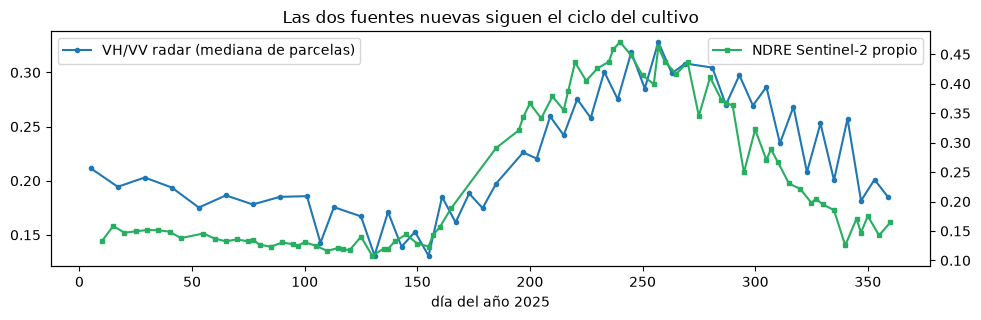

In [2]:
s2 = pd.read_csv(RAIZ / E9 / "s2_l2a_parcela_fecha.csv", parse_dates=["fecha"])
s2 = s2[(s2.n_pix > 0) & (s2.n_valid >= 0.5 * s2.n_pix)].copy()
s2["ndvi"] = (s2.B08 - s2.B04) / (s2.B08 + s2.B04)
s2["ndre"] = (s2.B8A - s2.B05) / (s2.B8A + s2.B05)
s2 = s2.groupby(["ID_POLIGONO", "fecha"], as_index=False)[["ndvi", "ndre"]].mean()
ref = bas[(bas.sensor == "Sentinel-2") & bas.ndvi_promedio.notna() & bas.fecha.dt.year.eq(2025)][["ID_POLIGONO", "fecha", "ndvi_promedio"]]
m = s2.merge(ref, on=["ID_POLIGONO", "fecha"])
VALID = {"pares": len(m), "pearson": m.ndvi.corr(m.ndvi_promedio), "dif_media": (m.ndvi - m.ndvi_promedio).mean(),
         "dif_abs_mediana": (m.ndvi - m.ndvi_promedio).abs().median()}
print({k: round(v, 4) for k, v in VALID.items()})
assert VALID["pearson"] > 0.99
fechas = s2[s2.fecha.dt.month.between(4, 10)].groupby("ID_POLIGONO").size()
print(f"Fechas útiles abril–octubre por parcela tras máscara: mínimo {fechas.min()}, mediana {fechas.median():.0f}")

s1 = pd.read_csv(RAIZ / E9 / "s1_rtc_parcela_fecha.csv", parse_dates=["fecha"])
s1 = s1[s1.n_valid > 0].assign(cr=lambda d: d.vh / d.vv)
aef = pd.read_csv(RAIZ / E9 / "alphaearth_parcela_anio.csv")
print("Radar: parcelas", s1.ID_POLIGONO.nunique(), "| AlphaEarth 2025: parcelas", aef[aef.year.eq(2025)].ID_POLIGONO.nunique())

med_cr = s1.groupby(s1.fecha.dt.dayofyear).cr.median()
med_ndre = s2.groupby(s2.fecha.dt.dayofyear).ndre.median()
fig, ax = plt.subplots(figsize=(10, 3.3))
ax.plot(med_cr.index, med_cr, "o-", ms=3, label="VH/VV radar (mediana de parcelas)")
ax2 = ax.twinx(); ax2.plot(med_ndre.index, med_ndre, "s-", ms=3, color="#27ae60", label="NDRE Sentinel-2 propio")
ax.set_xlabel("día del año 2025"); ax.legend(loc="upper left"); ax2.legend(loc="upper right")
ax.set_title("Las dos fuentes nuevas siguen el ciclo del cultivo"); plt.tight_layout(); plt.show()

**Resultado.** La extracción reproduce el NDVI entregado con correlación >0.99. La diferencia
media pequeña es esperable por resolución (20 m frente a la del proveedor) y por el
tratamiento del desplazamiento de reflectancia; no afecta contrastes entre vecinas. Radar y
borde rojo suben con el cultivo desde junio, alcanzan su máximo en septiembre y bajan con la
senescencia. Miden el ciclo, no ruido.

## 2. Los cinco candidatos, con la receta registrada

Misma maquinaria que EXP_08. **Curva:** mediana diaria, mediana móvil y descriptores (base
abril–mayo, umbral del 50 %, integral). Todas se cortan al 31 de octubre. **Contraste:**
valor de la parcela − mediana de las vecinas (entre las 197) a <1 km, con ≥2 vecinas.

In [3]:
DIAS = np.arange(1, 366)
IDS = T.index.to_numpy(); XY = T[["x_m", "y_m"]].to_numpy(); DIST = np.linalg.norm(XY[:, None] - XY[None], axis=2)


def contraste(s, radio=1000, minimo=2):
    s = s.reindex(IDS); out = pd.Series(np.nan, index=IDS)
    for i, p in enumerate(IDS):
        v = IDS[(DIST[i] < radio) & (DIST[i] > 0)]
        if len(v) >= minimo and np.isfinite(s[p]):
            out[p] = s[p] - s[v].median()
    return out


def curva(doy, val, ventana, minimo):
    s = pd.Series(np.asarray(val)).groupby(np.asarray(doy)).median().reindex(DIAS)
    return s.rolling(ventana, center=True, min_periods=minimo).median().interpolate(limit_area="inside")


def integral(c, fin_max=304):
    c = c.loc[:fin_max]; base = c.loc[91:150].median(); t = c.loc[150:min(330, fin_max)]
    if t.isna().all() or np.isnan(base):
        return np.nan
    pk, dp = t.max(), t.idxmax(); u = base + 0.5 * (pk - base)
    sub = c.loc[150:dp]; ini = sub[sub >= u].index.min(); baj = c.loc[dp:fin_max]
    fin = baj[baj < u].index.min() if (baj < u).any() else fin_max
    return (c.loc[ini:fin] - base).clip(lower=0).sum()


def integrales(df, col, ventana, minimo):
    return pd.Series({p: integral(curva(g.fecha.dt.dayofyear, g[col], ventana, minimo)) for p, g in df.groupby("ID_POLIGONO")})


pl = pro[pro.ndvi_promedio.notna() & pro.porcentaje_nubosidad.le(20)]
K = pd.DataFrame({"K1": contraste(integrales(pl, "ndvi_promedio", 15, 3)),
                  "K2": contraste(integrales(s2, "ndre", 21, 2)),
                  "K3": contraste(integrales(s1, "cr", 25, 2))})
A25 = aef[aef.year.eq(2025)].set_index("ID_POLIGONO").reindex(IDS)[[f"A{i:02d}" for i in range(64)]]
CA = pd.DataFrame({c: contraste(A25[c]) for c in A25}); ok = CA.notna().all(axis=1)
Xc = CA[ok].to_numpy() - CA[ok].to_numpy().mean(0)
_, sv, vt = np.linalg.svd(Xc, full_matrices=False)
K["K4"] = pd.Series(Xc @ vt[0], index=CA.index[ok]).reindex(IDS)
both = K.K4.notna() & K.K1.notna()
if np.corrcoef(K.K4[both], K.K1[both])[0, 1] < 0:   # signo fijado solo con X
    K["K4"] = -K.K4
hist = pd.concat([contraste(V[f"H{y}_S2_ndvi_integral"]) for y in (2022, 2023, 2024)], axis=1)
K["K5"] = hist.mean(axis=1).where(hist.notna().any(axis=1))
print("Varianza del contraste AlphaEarth explicada por su primer componente:", round(sv[0] ** 2 / (sv ** 2).sum(), 3))
display(pd.DataFrame({"con valor (197)": K.notna().sum(), "ocultas con valor (59)": K.loc[OCULTAS].notna().sum()}))
display(K.corr(method="spearman").round(2))
assert (K.loc[OCULTAS].notna().sum() == 50).all()

Varianza del contraste AlphaEarth explicada por su primer componente: 0.182


,con valor (197),ocultas con valor (59)
K1,158,50
K2,158,50
K3,158,50
K4,156,50
K5,158,50


,K1,K2,K3,K4,K5
K1,1.00,0.64,0.38,0.16,0.17
K2,0.64,1.00,0.24,0.29,0.17
K3,0.38,0.24,1.00,0.05,0.11
K4,0.16,0.29,0.05,1.00,0.22
K5,0.17,0.17,0.11,0.22,1.00


**Solo con X:** K1 y K2 (verdor y borde rojo) comparten buena parte de su información.
Radar, embeddings e historia aportan información casi independiente. Ninguna correlación
anterior usa rendimientos.

## 3. Evaluación registrada: dos juegos de particiones

Predicción = MIX + Σβ·z, con β = (ZᵀZ + 10·I)⁻¹Zᵀe y residuos e de MIX por validación interna.
En los candidatos de una variable, las parcelas de entrenamiento sin contraste no entran al
ajuste, idéntico a EXP_08. Las **particiones nuevas** (semilla 20261009) comprueban que el
resultado no dependa de la suerte de las históricas.

In [4]:
CANDS = {"K1": ["K1"], "K2": ["K2"], "K3": ["K3"], "K4": ["K4"], "K5": ["K5"], "K6": ["K1", "K2", "K3", "K4", "K5"]}
PARTS = {"históricas": ("data/validacion_03/particiones_externas.csv", "data/validacion_03/particiones_internas.csv"),
         "nuevas": (E9 + "particiones_externas_nuevas.csv", E9 + "particiones_internas_nuevas.csv")}


def mun_pred(a, t):
    return t.Municipio.map(a.groupby("Municipio").y.mean()).fillna(a.y.mean()).to_numpy()


def idw(a, t, k=20, p=2):
    d = np.linalg.norm(t[["x_m", "y_m"]].to_numpy()[:, None] - a[["x_m", "y_m"]].to_numpy()[None], axis=2)
    idx = np.argsort(d, 1)[:, :min(k, len(a))]; w = 1 / np.maximum(np.take_along_axis(d, idx, 1), 1.0) ** p
    w /= w.sum(1, keepdims=True); return (w * a.y.to_numpy()[idx]).sum(1)


def mix(a, t):
    return 0.5 * mun_pred(a, t) + 0.5 * idw(a, t)


def preparar(nombre):
    E, I = [pd.read_csv(RAIZ / p) for p in PARTS[nombre]]; out = []
    for (r, f), g in E.groupby(["repeticion", "pliegue"]):
        tr = g.loc[g.rol.eq("entrenamiento"), "ID_POLIGONO"].to_numpy(); va = g.loc[g.rol.eq("validacion"), "ID_POLIGONO"].to_numpy()
        a, t = L.loc[tr], L.loc[va]; e = pd.Series(np.nan, index=tr)
        for _, gg in I[(I.repeticion == r) & (I.pliegue == f)].groupby("pliegue_interno"):
            vi = gg.loc[gg.rol.eq("validacion"), "ID_POLIGONO"].to_numpy()
            e.loc[vi] = L.loc[vi].y.to_numpy() - mix(L.loc[gg.loc[gg.rol.eq("entrenamiento"), "ID_POLIGONO"]], L.loc[vi])
        assert e.notna().all()
        out.append(dict(r=int(r), tr=tr, va=va, mix=mix(a, t), mun=mun_pred(a, t), y=t.y.to_numpy(),
                        visto=t.Municipio.isin(set(a.Municipio)).to_numpy(), muni=t.Municipio.to_numpy(), e=e))
    return out


def corr(Kdf, cols, s, alpha=10.0):
    X = Kdf.loc[s["tr"], cols]; med, sd = X.median(), X.std(); e = s["e"]
    if len(cols) == 1:
        keep = X[cols[0]].notna(); X, e = X[keep], e[keep]
    Zm = ((X - med) / sd).fillna(0.0).to_numpy()
    beta = np.linalg.solve(Zm.T @ Zm + alpha * np.eye(len(cols)), Zm.T @ e.to_numpy())
    return ((Kdf.loc[s["va"], cols] - med) / sd).fillna(0.0).to_numpy() @ beta, beta


def oof(SPL, Kdf):
    filas = []
    for s in SPL:
        preds = {"MIX": s["mix"], "MUN": s["mun"], **{c: s["mix"] + corr(Kdf, cols, s)[0] for c, cols in CANDS.items()}}
        for mdl, p in preds.items():
            filas.append(pd.DataFrame({"modelo": mdl, "rep": s["r"], "ID_POLIGONO": s["va"], "obs": s["y"], "pred": p,
                                       "visto": s["visto"], "Municipio": s["muni"]}))
    return pd.concat(filas, ignore_index=True)


def resumen(o):
    out = []
    for esc, oo in [("SEEN135", o[o.visto]), ("FULL138", o)]:
        e = oo.assign(e=oo.pred - oo.obs)
        rm = e.groupby(["modelo", "rep"]).e.apply(lambda s: np.sqrt((s ** 2).mean())).unstack()
        ma = e.groupby(["modelo", "rep"]).e.apply(lambda s: s.abs().mean()).unstack()
        for mdl, g in e.groupby("modelo"):
            ch = g.Municipio.eq("Chignahuapan")
            out.append({"escenario": esc, "modelo": mdl, "RMSE": np.sqrt((g.e ** 2).mean()), "MAE": g.e.abs().mean(),
                        "reps RMSE<MIX": int((rm.loc[mdl] < rm.loc["MIX"]).sum()), "reps MAE≤MIX": int((ma.loc[mdl] <= ma.loc["MIX"]).sum()),
                        "RMSE Chignahuapan": np.sqrt((g.e[ch] ** 2).mean()), "RMSE resto": np.sqrt((g.e[~ch] ** 2).mean())})
    return pd.DataFrame(out).set_index(["escenario", "modelo"])


SPL, OOF, RES = {}, {}, {}
for nombre in PARTS:
    SPL[nombre] = preparar(nombre); OOF[nombre] = oof(SPL[nombre], K); RES[nombre] = resumen(OOF[nombre])
    print(f"Particiones {nombre}"); display(RES[nombre].round(4).sort_values(["escenario", "RMSE"]))
H, N = RES["históricas"], RES["nuevas"]
assert abs(H.loc[("SEEN135", "MIX"), "RMSE"] - 0.48719651492001237) < 1e-9
assert abs(H.loc[("SEEN135", "K1"), "RMSE"] - 0.4816) < 2e-4 and abs(N.loc[("SEEN135", "K1"), "RMSE"] - 0.4807) < 2e-4
BETAS = {c: np.array([corr(K, cols, s)[1] for s in SPL["históricas"]]) for c, cols in CANDS.items()}
display(pd.DataFrame({c: {"β medio": np.round(b.mean(0), 3).tolist(), "fracción negativa": np.round((b < 0).mean(0), 2).tolist()}
                      for c, b in BETAS.items()}).T)

Particiones históricas


RMSE     MAE  reps RMSE<MIX  reps MAE≤MIX  RMSE Chignahuapan  RMSE resto
escenario modelo                                                                            
FULL138   K1      0.4875  0.3394             10            10             0.5681      0.3842
          K2      0.4902  0.3385              8             9             0.5667      0.3933
          K3      0.4920  0.3410              8             6             0.5754      0.3844
          K6      0.4925  0.3451              7             2             0.5685      0.3963
          MIX     0.4938  0.3417              0            10             0.5736      0.3920
          K5      0.4950  0.3455              3             0             0.5723      0.3968
          K4      0.4965  0.3439              3             2             0.5782      0.3917
          MUN     0.5118  0.3354              0            10             0.5902      0.4127
SEEN135   K1      0.4816  0.3330             10             7             0.5681      0.3623
          K2      0.4846  0.3323              7             8             0.5667      0.3728
          K3      0.4858  0.3340              8             6             0.5754      0.3612
          K6      0.4867  0.3388              4             1             0.5685      0.3756
          MIX     0.4872  0.3342              0            10             0.5736      0.3683
          K5      0.4881  0.3378              5             0             0.5723      0.3730
          K4      0.4899  0.3365              3             2             0.5782      0.3680
          MUN     0.4934  0.3213              1            10             0.5902      0.3565

Particiones nuevas


RMSE     MAE  reps RMSE<MIX  reps MAE≤MIX  RMSE Chignahuapan  RMSE resto
escenario modelo                                                                            
FULL138   K1      0.4867  0.3411             10             9             0.5644      0.3878
          K3      0.4898  0.3415              9             7             0.5697      0.3876
          K2      0.4906  0.3425              7             5             0.5635      0.3989
          MIX     0.4923  0.3430              0            10             0.5692      0.3948
          K6      0.4931  0.3473              5             2             0.5655      0.4024
          K4      0.4934  0.3433              6             5             0.5717      0.3937
          K5      0.4937  0.3469              4             1             0.5681      0.4000
          MUN     0.5110  0.3356              0            10             0.5883      0.4135
SEEN135   K1      0.4807  0.3347             10             6             0.5644      0.3661
          K3      0.4835  0.3347              9             6             0.5697      0.3649
          K2      0.4848  0.3364              6             4             0.5635      0.3789
          MIX     0.4857  0.3357              0            10             0.5692      0.3716
          K4      0.4867  0.3360              6             5             0.5717      0.3704
          K5      0.4869  0.3395              5             1             0.5681      0.3768
          K6      0.4872  0.3411              5             1             0.5655      0.3822
          MUN     0.4922  0.3213              1            10             0.5883      0.3564

,β medio,fracción negativa
K1,[-0.095],[1.0]
K2,[-0.088],[1.0]
K3,[-0.077],[1.0]
K4,[-0.076],[0.98]
K5,[0.059],[0.02]
K6,"[-0.056, -0.033, -0.054, -0.068, 0.09]","[1.0, 0.9, 1.0, 0.98, 0.0]"


**Lectura.**

* **K1 sigue siendo el mejor** y repite su mejora en particiones que nunca se usaron:
  ≈0.005 t/ha menos RMSE que MIX en SEEN, 10/10 repeticiones en ambos juegos, y MAE no
  peor que MIX.
* **Borde rojo (K2) y radar (K3) mejoran a MIX, pero menos que K1.** El borde rojo comparte
  información con el NDVI de Planet. El radar aporta algo propio, con el mismo signo: más
  estructura que las vecinas → menos rendimiento.
* **Embeddings (K4) e historia (K5) no mejoran a MIX.** La historia tiene **signo
  contrario**: una parcela habitualmente más verde que sus vecinas tiende a rendir *más*. El
  exceso de verdor *en el año del ciclo* tiende a rendir *menos*. La combinación es
  agronómicamente coherente con "buena parcela" frente a "exceso vegetativo o maleza este
  año", pero no basta para predecir.
* **Combinar todo (K6) empeora a K1:** más pendientes cuestan más de lo que aportan con 138
  parcelas. Es la misma lección que MIX afinado en EXP_08.

## 4. Nulo de familia: ¿el mejor de seis candidatos podría salir por azar?

Se permutan juntas las columnas K1–K5 dentro de cada municipio, se recalculan los seis
candidatos y se guarda **el menor RMSE SEEN de los seis**. Este nulo descuenta haber probado
seis opciones, y es más exigente que el de EXP_08, que evaluaba una sola.

,RMSE SEEN,p de familia
K1,0.4816,0.130
K2,0.4846,0.255
K3,0.4858,0.380
K4,0.4899,0.955
K5,0.4881,0.720
K6,0.4867,0.465


Nulo (mínimo de seis): media 0.4858, percentil 5 0.4786; MIX 0.4872


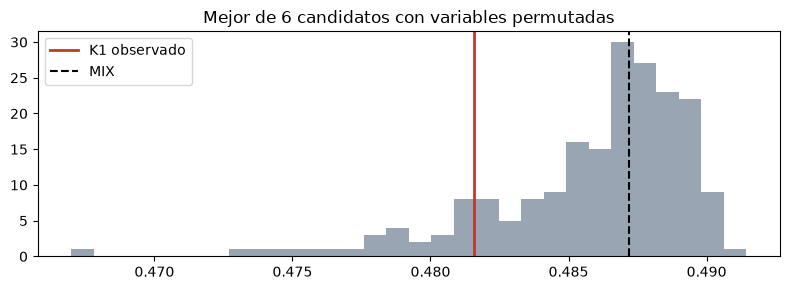

In [5]:
def rmse_seen(Kdf):
    se = {c: [] for c in CANDS}; vis = []
    for s in SPL["históricas"]:
        for c, cols in CANDS.items():
            se[c].append((s["mix"] + corr(Kdf, cols, s)[0] - s["y"]) ** 2)
        vis.append(s["visto"])
    vis = np.concatenate(vis); return {c: np.sqrt(np.concatenate(v)[vis].mean()) for c, v in se.items()}


def permutar(Kdf, rng):
    out = Kdf.copy()
    for _, g in T.groupby("Municipio"):
        idx = g.index.to_numpy(); out.loc[idx] = Kdf.loc[rng.permutation(idx)].to_numpy()
    return out


rng = np.random.default_rng(SEMILLA)
obs = rmse_seen(K)
nulo = np.array([min(rmse_seen(permutar(K, rng)).values()) for _ in range(N_PERM)])
P_FAM = {c: (nulo <= v).mean() for c, v in obs.items()}
display(pd.DataFrame({"RMSE SEEN": obs, "p de familia": P_FAM}).round(4))
print(f"Nulo (mínimo de seis): media {nulo.mean():.4f}, percentil 5 {np.quantile(nulo, .05):.4f}; MIX {H.loc[('SEEN135', 'MIX'), 'RMSE']:.4f}")
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(nulo, bins=30, color="#9aa5b3"); ax.axvline(obs["K1"], color="#c0392b", lw=2, label="K1 observado")
ax.axvline(H.loc[("SEEN135", "MIX"), "RMSE"], color="k", ls="--", label="MIX"); ax.legend(); ax.set_title("Mejor de 6 candidatos con variables permutadas")
plt.tight_layout(); plt.show()
assert 0.10 < P_FAM["K1"] < 0.20

**Resultado.** Con seis candidatos de ruido, el mejor de ellos ya baja a MIX casi la mitad
de lo que baja K1. **K1 queda con p ≈ 0.13 de familia.** La evidencia es consistente en
dirección, pero no fuerte. Es menos que en EXP_08 porque ahora se descuenta haber mirado
seis opciones, incluido el propio K1, que ya se conocía.

## 5. Concentración y regla de decisión registrada

In [6]:
def concentracion(o, c):
    w = o[o.visto & o.modelo.isin(["MIX", c])].pivot_table(index=["ID_POLIGONO", "rep"], columns="modelo", values="pred")
    w = w.join(o[o.visto].groupby(["ID_POLIGONO", "rep"]).obs.first())
    p = ((w[c] - w.obs) ** 2 - (w["MIX"] - w.obs) ** 2).groupby("ID_POLIGONO").sum().sort_values()
    return {"neto": p.sum(), "sin 2 mejores": p.iloc[2:].sum(), "sin 5 mejores": p.iloc[5:].sum(), "más favorecidas": ", ".join(p.index[:3])}


o_h = OOF["históricas"]
filas = []
for c in CANDS:
    co = concentracion(o_h, c)
    filas.append({"candidato": c, "RMSE SEEN": H.loc[("SEEN135", c), "RMSE"],
                  "(a) p familia ≤ 0.10": P_FAM[c] <= 0.10,
                  "(b) ≥8/10 reps históricas y nuevas": H.loc[("SEEN135", c), "reps RMSE<MIX"] >= 8 and N.loc[("SEEN135", c), "reps RMSE<MIX"] >= 8,
                  "(c) MAE ≤ MIX": H.loc[("SEEN135", c), "MAE"] <= H.loc[("SEEN135", "MIX"), "MAE"],
                  "(d) sigue ganando sin 2 mejores": co["sin 2 mejores"] < 0, **co})
REGLA = pd.DataFrame(filas).set_index("candidato")
REGLA["cumple todo"] = REGLA.filter(like="(").all(axis=1)
display(REGLA.round(3))
assert not REGLA["cumple todo"].any()
assert REGLA.loc["K1", ["(b) ≥8/10 reps históricas y nuevas", "(c) MAE ≤ MIX", "(d) sigue ganando sin 2 mejores"]].all()
print(f"Tiempo total: {(time.time() - T0) / 60:.1f} min")

,RMSE SEEN,(a) p familia ≤ 0.10,(b) ≥8/10 reps históricas y nuevas,(c) MAE ≤ MIX,(d) sigue ganando sin 2 mejores,neto,sin 2 mejores,sin 5 mejores,más favorecidas,cumple todo
candidato,,,,,,,,,,
K1,0.482,False,True,True,True,-7.331,-1.726,3.813,"AGC_162, AGC_172, AGC_049",False
K2,0.485,False,False,True,False,-3.444,2.571,10.597,"AGC_133, AGC_049, AGC_024",False
K3,0.486,False,True,True,False,-1.822,4.096,9.706,"AGC_069, AGC_049, AGC_127",False
K4,0.490,False,False,False,False,3.552,10.373,15.046,"AGC_015, AGC_024, AGC_049",False
K5,0.488,False,False,False,False,1.188,5.412,9.654,"AGC_171, AGC_127, AGC_005",False
K6,0.487,False,False,False,False,-0.644,10.032,19.497,"AGC_049, AGC_026, AGC_133",False


Tiempo total: 4.4 min


## 6. Decisión y qué significa para el proyecto

**Aplicando la regla registrada:** ningún candidato cumple las cuatro condiciones. K1 cumple
(b), (c) y (d), pero no (a): p de familia 0.13 > 0.10. Por lo tanto, **la recomendación
formal es MIX, con K1 como candidato con reservas.** No se cambia el umbral después de ver el
resultado.

**Qué se aprende y sirve para el reporte:**

1. **Los datos entregados bastan.** Probamos borde rojo, radar, embeddings y máscara de nubes
   propia, con extracción validada contra el dataset (r > 0.99). Ninguna fuente externa
   superó al contraste del NDVI de Planet entregado. Esto responde la pregunta inicial del
   plan del equipo, *¿alcanza lo que nos dan o hay que justificar datos nuevos?*, con
   evidencia y no con una suposición.
2. **El patrón de signos es una respuesta interesante a las preguntas guía.** Lo útil no es el
   verdor absoluto, sino el verdor *relativo a las vecinas*. En el año del ciclo, el exceso se
   asocia con menor rendimiento, con NDVI, borde rojo y radar de acuerdo. Históricamente, una
   parcela más verde que su entorno tiende a rendir más.
3. **Más variables empeoran.** K6 confirma que, con 138 etiquetas, el modelo final debe ser
   simple.

**Decisión que corresponde al equipo, no a este cuaderno:** entre MIX (la regla) y MIX + K1
(mejora consistente de ~1 % en RMSE en dos juegos de particiones, con evidencia de familia
débil). Si la métrica oficial es RMSE o R², el costo esperado de elegir K1 es bajo: la
corrección mediana es de centésimas de t/ha. Si es MAE, MUN sigue siendo la referencia más
fuerte.

## Referencias (APA 7)

Brown, C. F., Kazmierski, M. R., Pasquarella, V. J., et al. (2025). *AlphaEarth Foundations: An
embedding field model for accurate and efficient global mapping from sparse label data*
[Prepublicación]. arXiv. https://arxiv.org/abs/2507.22291

Microsoft. (s. f.). *Planetary Computer: Sentinel-2 Level-2A; Sentinel-1 Radiometrically
Terrain Corrected (RTC)*. https://planetarycomputer.microsoft.com/catalog

Google & Google DeepMind. (2025). *Satellite Embedding V1* [Conjunto de datos, CC-BY 4.0].
https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_SATELLITE_EMBEDDING_V1_ANNUAL